# Ejemplo Cluster con Python

Para ilustrar la aplicación práctica del análisis de clustering, consideraremos un conjunto de datos que contiene la esperanza de vida de diferentes países y regiones. Este ejemplo práctico de análisis de clúster tiene como fin explorar y clasificar países en función de su esperanza de vida en diferentes etapas, diferenciada por sexo. A través de este análisis, buscamos identificar patrones y agrupaciones que nos permitan entender mejor las diferencias y similitudes en la esperanza de vida a nivel mundial. 

Utilizaremos Python, un poderoso lenguaje de programación y sus bibliotecas de análisis de datos para llevar a cabo este estudio. El proceso se desglosará en las siguientes etapas clave:


 1) Preparación de los datos: Cargar y visualizar la información contenida en el archivo $EsperanzaVida.xlsx$, estableciendo una comprensión inicial del conjunto de datos.
 2) Análisis exploratorio: Implementar un mapa de calor para identificar relaciones preliminares y patrones dentro del conjunto de datos.
 3) Cálculo de distancias: Generar y visualizar una matriz de distancias para evaluar la similitud entre las observaciones.
 4) Estandarización de datos: Preparar los datos para el análisis de clúster mediante la estandarización, facilitando así la comparabilidad entre las variables.
 5) Análisis de clúster jerárquico: Aplicar un enfoque jerárquico para agrupar los países y visualizar los resultados con un dendrograma.
 6) Selección del número de clústers: Utilizar métodos como el del codo y la silueta para determinar el número óptimo de clústers.
 7) Desarrollar un análisis no jerárquico mediante el algoritmo $k-means$.
 8) Evalua la calidad de los grupos creados
 9) Caracterización de clústers: Describir las propiedades y características distintivas de cada clúster identificado.
 
 Procedemos por tanto con el primer punto (Preparación de los datos) e importamos las librerías que vamos a utilizar y la cargamos de los datos.


In [6]:
# Importamos las bibliotecas necesarias
import os
import pandas as pd    
import seaborn as sns  
import matplotlib.pyplot as plt  
import numpy as np
from scipy.spatial import distance
from sklearn.preprocessing import StandardScaler
import scipy.cluster.hierarchy as sch
from scipy.cluster.hierarchy import fcluster
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import silhouette_samples
from scipy.spatial.distance import pdist, squareform
import warnings

# Establecer el nivel de advertencias a "ignore" para ignorar todas las advertencias
warnings.filterwarnings("ignore")

# Establecemos la ubicación de nuestro directorio de trabajo
os.chdir(r'C:\Users\danie\Desktop\Titulo propio 1\M2\Datos')


In [7]:
# Leemos el archivo de Excel en un DataFrame
df = pd.read_excel('EsperanzaVida.xlsx')

# Visualizamos el DataFrame para verificar los datos
df



,PAIS,m0,m25,m50,m75,w0,w25,w50,w75
0,Algeria,63,51,30,13,67,54,34,15
1,Cameroon,34,29,13,5,38,32,17,6
2,Madagascar,38,30,17,7,38,34,20,7
3,Mauritius,59,42,20,6,64,46,25,8
4,Reunion,56,38,18,7,62,46,25,10
5,Seychelles,62,44,24,7,69,50,28,14
6,South_Africa,65,44,22,7,72,50,27,9
7,Tunisia,56,46,24,11,63,54,33,19
8,Canada,69,47,24,8,75,53,29,10
9,Costa_Rica,65,48,26,9,68,50,27,10


In [8]:
# Configuramos 'PAIS' como el índice del DataFrame
df = df.set_index('PAIS')

## Visualizamos las primeras filas del DataFrame para verificar los datos
df.head()

,m0,m25,m50,m75,w0,w25,w50,w75
PAIS,,,,,,,,
Algeria,63,51,30,13,67,54,34,15
Cameroon,34,29,13,5,38,32,17,6
Madagascar,38,30,17,7,38,34,20,7
Mauritius,59,42,20,6,64,46,25,8
Reunion,56,38,18,7,62,46,25,10


2) Análisis exploratorio: Implementar un mapa de calor para identificar relaciones preliminares y patrones dentro del conjunto de datos.

Construimos un mapa de calor, donde se representan de manera ordenada los valores observados, así como un proceso de cluster jerárquico donde se muestran los diferentes pasos iterativos de unión de observaciones.

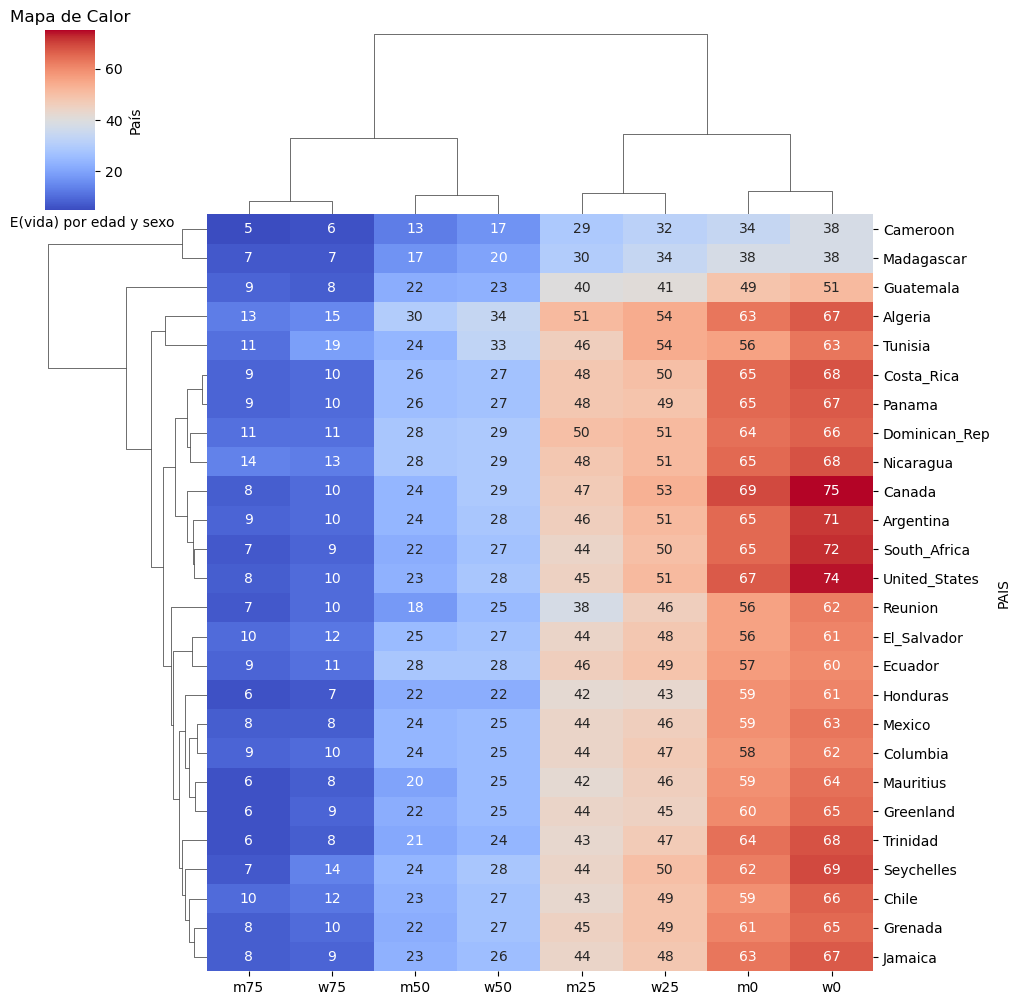

In [9]:
# Creamos el mapa de calor (heatmap) donde se representan de manera ordenada los 
# valores observados, así como un proceso de cluster jerárquico donde se muestran 
# los diferentes pasos iterativos de unión de observaciones y variables.

sns.clustermap(df, cmap='coolwarm', annot=True)
# Agregamos un título al gráfico
plt.title('Mapa de Calor')
# Etiquetamos el eje x
plt.xlabel('          E(vida) por edad y sexo')
# Etiquetamos el eje y
plt.ylabel('País')
# Mostramos el gráfico
plt.show()

 3) Cálculo de distancias: Generar y visualizar una matriz de distancias para evaluar la similitud entre las observaciones.
 
 Una vez representados los datos y un proceso jerárquico preliminar vamos a calcular la matriz de distancias (Euclídeas) entre las observaciones (con los valores sin estandarizar)


In [10]:
# Calculamos distancias sin estandarizar
# Calcula la matriz de distancias Euclidianas entre las observaciones
distance_matrix = distance.cdist(df, df, 'euclidean')
# Crea un DataFrame a partir de la matriz de distancias con los índices de df
distance_df = pd.DataFrame(distance_matrix, index=df.index, columns=df.index)
# La distance_matrix es una matriz 2D que contiene las distancias Euclidianas 
# entre todas las parejas de observaciones.

# Seleccionamos las primeras 10 filas y columnas de la matriz de distancias
distance_small = distance_matrix[:10, :10]
# Agregamos los nombres de índice a la matriz de distancias
distance_small = pd.DataFrame(distance_small, index=df.index[:10], columns=df.index[:10])
# Redondeamos los valores en la matriz de distancias
distance_small_rounded = distance_small.round(2)

distance_small_rounded

PAIS,Algeria,Cameroon,Madagascar,Mauritius,Reunion,Seychelles,South_Africa,Tunisia,Canada,Costa_Rica
PAIS,,,,,,,,,,
Algeria,0.00,58.08,52.65,21.19,24.35,13.38,16.70,12.12,15.10,11.66
Cameroon,58.08,0.00,7.14,42.24,38.03,51.03,53.48,49.64,60.41,53.36
Madagascar,52.65,7.14,0.00,37.96,33.81,46.38,49.14,44.53,55.86,48.50
Mauritius,21.19,42.24,37.96,0.00,6.16,10.77,11.40,17.78,18.30,12.53
Reunion,24.35,38.03,33.81,6.16,0.00,14.07,15.94,18.06,22.83,17.46
Seychelles,13.38,51.03,46.38,10.77,14.07,0.00,6.93,12.57,11.00,7.14
South_Africa,16.70,53.48,49.14,11.40,15.94,6.93,0.00,18.38,7.28,7.28
Tunisia,12.12,49.64,44.53,17.78,18.06,12.57,18.38,0.00,20.52,15.84
Canada,15.10,60.41,55.86,18.30,22.83,11.00,7.28,20.52,0.00,9.17


Por si se desea profundizar, la función anterior $cdist()$ admite las siguientes distancias: $Euclidean$, $Manha-ttan$, $Minkowski$, $Chebyshev$, $Cosine$, $Hamming$, $Jaccard$, $Correlation$, $Mahalanobis$, $Canberra$.

Representemos ahora mediante escalas de color la distancia entre todas las observaciones, esto nos ayudará a detectar grupos de observaciones con grandes distancias entre sí.

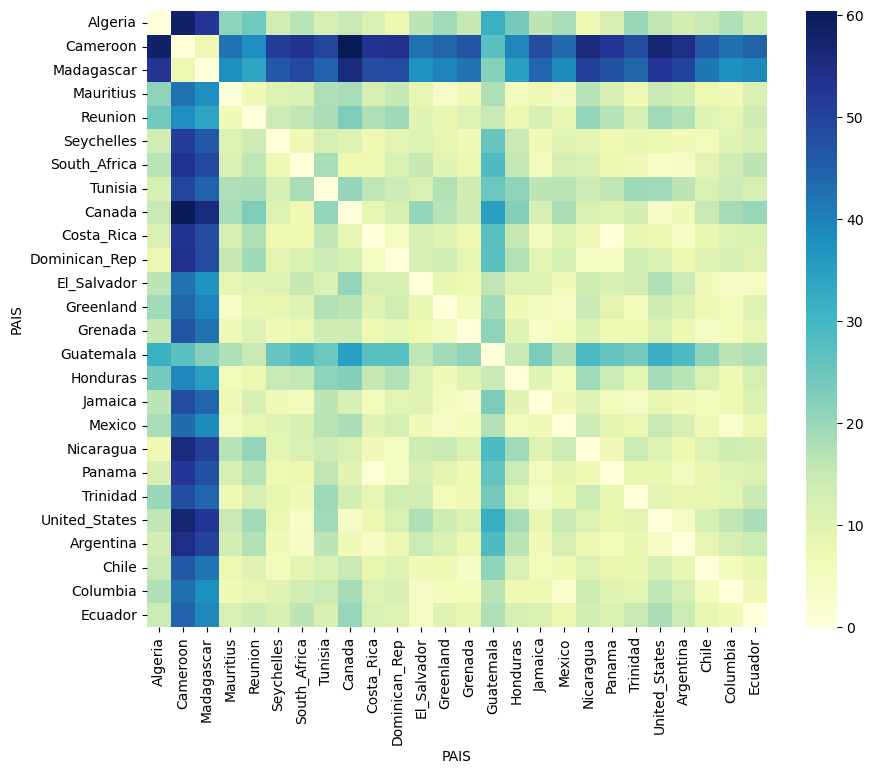

In [11]:
# Representamos gráficamente la matriz de distancias

# Crea una nueva figura para el gráfico con un tamaño específico
plt.figure(figsize=(10, 8))
# Genera un mapa de calor usando Seaborn
# - `distance_df`: DataFrame de pandas que contiene los datos para el mapa de calor.
# - `annot=False`: No muestra las anotaciones (valores de los datos) en las celdas del mapa.
# - `cmap="YlGnBu"`: Utiliza la paleta de colores "Yellow-Green-Blue" para el mapa de calor.
# - `fmt=".1f"`: Formato de los números en las anotaciones, en este caso no se usan.
sns.heatmap(distance_df, annot=False, cmap="YlGnBu", fmt=".1f")
# Muestra el gráfico
plt.show()

Como podemos observar, hay dos países, Camerún y Madagascar, que tienen una distancia muy superior con el resto de los países.

Una herramienta eficaz para identificar y visualizar patrones entre los diferentes elementos de un conjunto de datos, son los mapas de calor que incorporan técnicas de reordenación basadas en la similitud. Estos métodos nos permiten agrupar los elementos más similares, es decir, aquellos con menor distancia entre sí, mejorando nuestra capacidad para detectar agrupaciones y relaciones clave en los datos.

El gráfico que presentaremos a continuación es un mapa de calor avanzado. Aplicaremos técnicas de clustering jerárquico para reordenar los datos de manera que los elementos similares se ubiquen cercanamente. Esta técnica realza la visualización, facilitando la identificación de grupos y patrones intrínsecos en los datos, crucial para una comprensión profunda y detallada del conjunto de datos analizado.

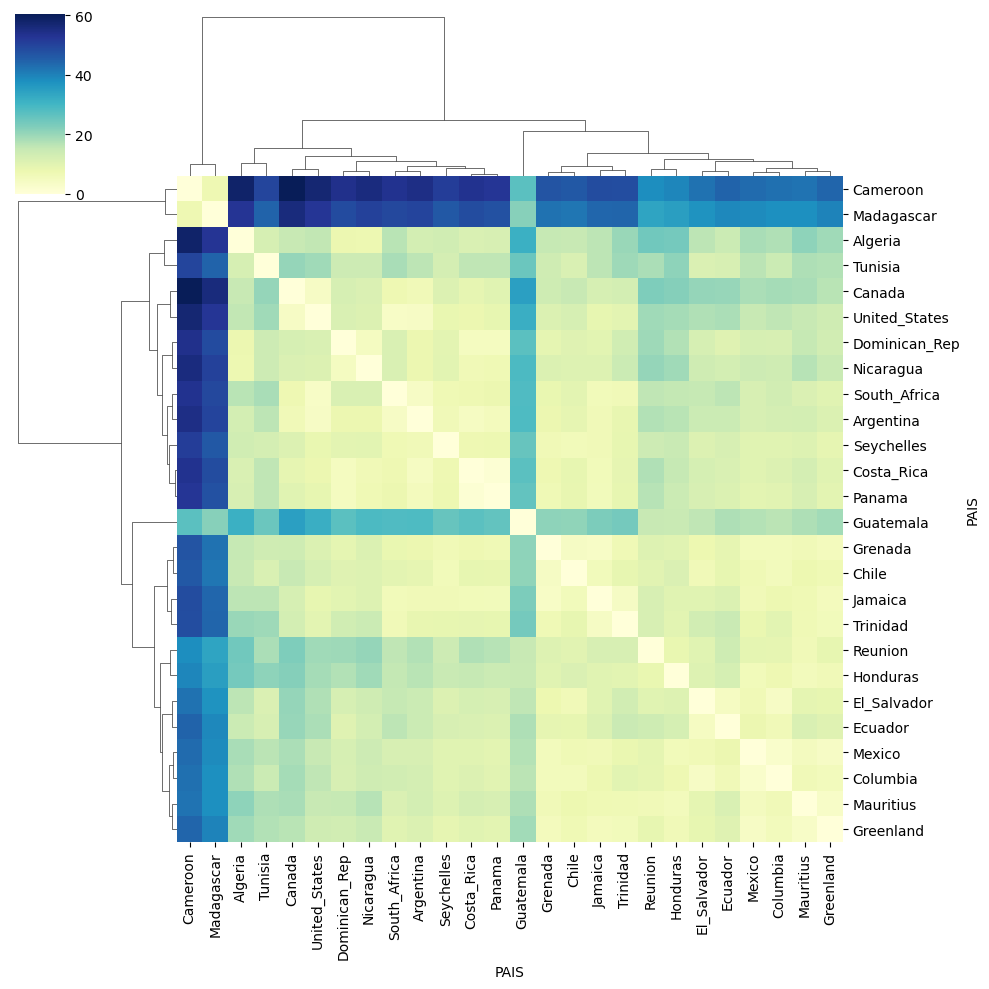

In [12]:
# Realizamos clustering jerárquico para obtener la matriz de enlace (linkage matrix). 
# Clustermap es una función compleja que combina un mapa de calor con dendrogramas para mostrar la agrupación de datos.
# Aquí, estamos usando el dataframe 'distance_df' que contiene las distancias euclidianas entre las observaciones.
# La opción 'cmap' establece la paleta de colores a 'YlGnBu', que es un gradiente de azules y verdes.
# La opción 'fmt' se usa para formatear las anotaciones numéricas, en este caso a un decimal.
# La opción 'annot=False' indica que no queremos anotaciones numéricas en las celdas del mapa de calor.
# La opción 'method' especifica el método de agrupamiento a usar, en este caso 'average' que calcula la media de las distancias.
linkage = sns.clustermap(distance_df, cmap="YlGnBu", fmt=".1f", annot=False, method='ward').dendrogram_row



 4) Estandarización de datos: Preparar los datos para el análisis de clúster mediante la estandarización, facilitando así la comparabilidad entre las variables.


Para que la distancia entre individuos no dependa de las unidades en las que están medidas las variables, y refleje mejor las relaciones entre dichos individuos, es conveniente estandarizar las variables. En este ejemplo, todas las variables estan medidas en la misma escala (años) pero no desde el mismo punto de partida, ya que la esperanza de vida se recoge en diferentes etapas.   

Recordamos que estandarizar una variable es restar su media y dividir por su desviación estándar a cada observación, para conseguir que todas las variables tengan media cero y desviación típica uno: 

\begin{equation}
    z_{ij} = \frac{x_{ij}- \overline{x}_j}{s_j}
\end{equation}

In [13]:
# Estandarizamos los datos
# Inicializamos el escalador de estandarizacion
scaler = StandardScaler()
    
# Ajustamos y transformamos el DataFrame para estandarizar las columnas
# 'fit_transform' primero calcula la media y la desviacion estandar de cada columna para luego realizar la estandarizacion.
df_std = pd.DataFrame(scaler.fit_transform(df), columns=df.columns)

# Asignamos el indice del DataFrame original 'df' al nuevo DataFrame 'df_std'
# Esto es importante para mantener la correspondencia de los indices de las filas despues de la estandarizacion.
df_std.index = df.index
df_std

,m0,m25,m50,m75,w0,w25,w50,w75
PAIS,,,,,,,,
Algeria,0.484661,1.485448,1.910752,2.144391,0.398812,1.268798,2.217004,1.752224
Cameroon,-3.169682,-2.963119,-2.860730,-1.635553,-2.905632,-3.000334,-2.707195,-1.554392
Madagascar,-2.665635,-2.760912,-1.738029,-0.690567,-2.905632,-2.612231,-1.838219,-1.186990
Mauritius,-0.019386,-0.334420,-0.896002,-1.163060,0.056973,-0.283614,-0.389925,-0.819588
Reunion,-0.397422,-1.143251,-1.457353,-0.690567,-0.170920,-0.283614,-0.389925,-0.084785
Seychelles,0.358649,0.069995,0.226699,-0.690567,0.626705,0.492592,0.479051,1.384822
South_Africa,0.736685,0.069995,-0.334651,-0.690567,0.968544,0.492592,0.189392,-0.452187
Tunisia,-0.397422,0.474410,0.226699,1.199405,-0.056973,1.268798,1.927345,3.221830
Canada,1.240732,0.676618,0.226699,-0.218074,1.310383,1.074747,0.768710,-0.084785


In [14]:
# Calculamos las distancias euclidianas por pares entre las filas del DataFrame estandarizado
# 'cdist' calcula la distancia euclidiana entre cada par de filas en 'df_std'.
# Esto resulta en una matriz de distancias donde cada elemento [i, j] es la distancia entre la fila i y la fila j.
distance_std = distance.cdist(df_std, df_std, 'euclidean') 

# Seleccionamos las primeras 10 filas y columnas de la matriz de distancias
distance_small = distance_std[:10, :10]
# Agregamos los nombres de índice a la matriz de distancias
distance_small = pd.DataFrame(distance_small, index=df.index[:10], columns=df.index[:10])
# Redondeamos los valores en la matriz de distancias
distance_small_rounded = distance_small.round(2)

distance_small_rounded

PAIS,Algeria,Cameroon,Madagascar,Mauritius,Reunion,Seychelles,South_Africa,Tunisia,Canada,Costa_Rica
PAIS,,,,,,,,,,
Algeria,0.00,11.60,10.02,6.19,6.32,4.09,5.00,2.83,4.00,3.66
Cameroon,11.60,0.00,1.87,6.56,6.02,8.69,8.28,10.38,9.64,9.02
Madagascar,10.02,1.87,0.00,5.50,4.90,7.42,7.13,8.94,8.40,7.66
Mauritius,6.19,6.56,5.50,0.00,1.39,2.89,1.78,5.64,3.17,2.93
Reunion,6.32,6.02,4.90,1.39,0.00,3.01,2.53,5.27,3.80,3.57
Seychelles,4.09,8.69,7.42,2.89,3.01,0.00,2.01,3.29,2.10,2.06
South_Africa,5.00,8.28,7.13,1.78,2.53,2.01,0.00,4.85,1.44,1.77
Tunisia,2.83,10.38,8.94,5.64,5.27,3.29,4.85,0.00,4.35,4.19
Canada,4.00,9.64,8.40,3.17,3.80,2.10,1.44,4.35,0.00,1.46


Podemos ver en la tabla anterior que las distancias son ahora menores, ya que en el proceso de estandarización, en este caso, reduce los valores en las variables. Podemos intentar de nuevo visualizar el mapa de calor de las distancias para datos estandarizados, primero sin ordenar y posteriormente ordenando los países de forma que estén próximos los más parecidos. Conviene preguntarse aquí: ¿cuál es la diferencia respecto al mapa de calor anterior?

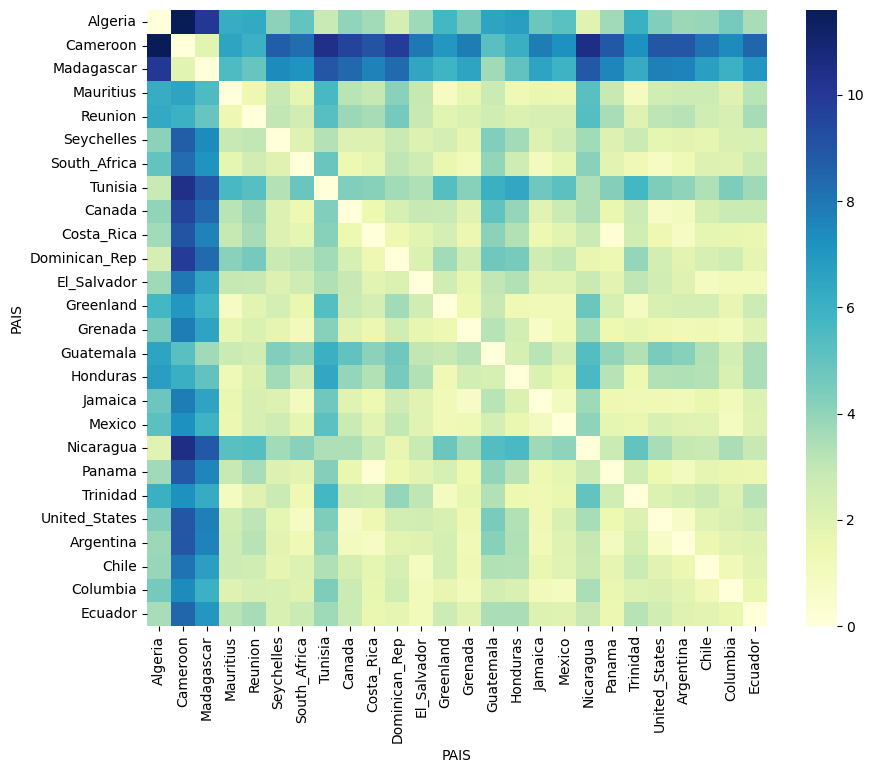

In [15]:
# Esto determina las dimensiones del grafico
plt.figure(figsize=(10, 8))

# Creamos un nuevo DataFrame para la matriz de distancias
# 'distance_std' se convierte en un DataFrame con indices y columnas correspondientes a 'df_std'
# Esto facilita la interpretacion del mapa de calor, ya que las filas y columnas estaran etiquetadas con los indices de 'df_std'
df_std_distance = pd.DataFrame(distance_std, index=df_std.index, columns=df_std.index)

# Generamos un mapa de calor utilizando Seaborn
# - 'df_std_distance': DataFrame que contiene los datos de distancia para visualizar.
# - 'annot=False': No muestra anotaciones numericas en cada celda del mapa de calor.
# - 'cmap="YlGnBu"': Define una paleta de colores en tonos de azul y verde para el mapa de calor.
# - 'fmt=".1f"': Formato de los numeros en las anotaciones, en este caso, un decimal.
sns.heatmap(df_std_distance, annot=False, cmap="YlGnBu", fmt=".1f")

# Mostramos el grafico resultante
plt.show()

 5) Análisis de clúster jerárquico: Aplicar un enfoque jerárquico para agrupar los países y visualizar los resultados con un dendrograma.

Volvemos a construir el mapa de calor avanzado donde implementamos un análisis cluster jerárquico, esta vez, sobre la matriz de distancias estandarizadas.

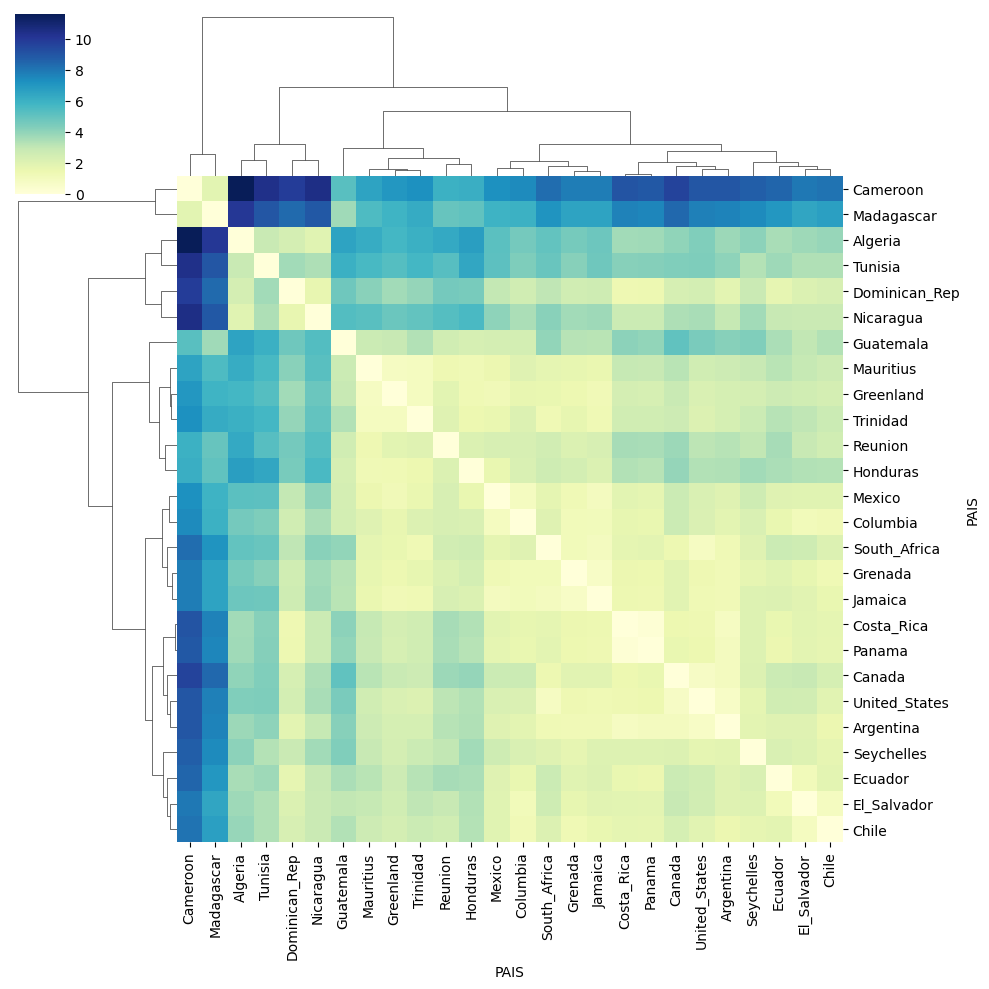

In [16]:

# Realizamos clustering jerárquico para obtener la matriz de enlace (linkage matrix) sobre las distancias estandarizadas. 
linkage = sns.clustermap(df_std_distance, cmap="YlGnBu", fmt=".1f", annot=False, method='ward').dendrogram_row


Procedemos ahora a la construcción de un dendograma aislado, sin representar el mapa de calor. 

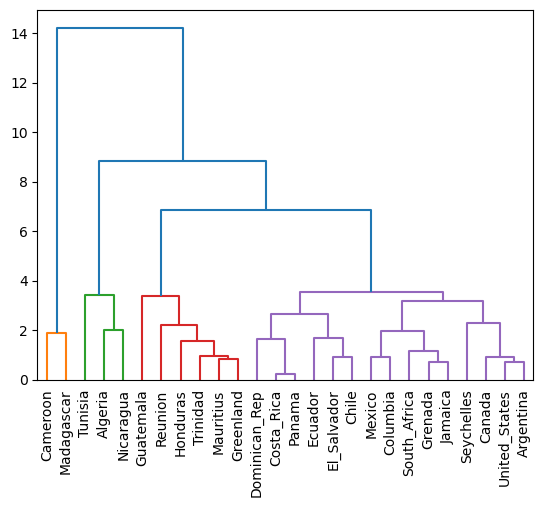

In [17]:
# Establecemos un umbral de color para el dendrograma
color_threshold = 5

linkage_matrix = sch.linkage(df_std, method='ward')  # Puedes elegir un metodo de enlace diferente si es necesario

# Creamos el dendrograma con el umbral de color especificado
dendrogram = sch.dendrogram(linkage_matrix, labels=df_std_distance.index.tolist(), leaf_rotation=90, color_threshold=color_threshold)

# Mostramos el dendrograma
plt.show()

En el dendrograma, los diferentes colores representan distintos conglomerados o grupos identificados por el algoritmo de agrupamiento jerárquico, utilizando el método de Ward. Cada color indica un grupo distinto, de modo que los puntos con el mismo color pertenecen al mismo grupo. La jerarquía del dendrograma se forma al fusionar progresivamente grupos más pequeños en otros más grandes, revelando así la estructura de agrupamiento subyacente.

La observación detallada de la estructura del dendrograma nos permite inferir el número más adecuado de clusters. Por ejemplo, en nuestro análisis, un número razonable de clusters podría ser cuatro. Esta conclusión se basa en que las fusiones que forman estos cuatro clusters ocurren a distancias relativamente cortas, indicando una mayor similitud dentro de cada grupo. Por otro lado, para que algunos de estos clusters se combinen entre sí, es necesario considerar distancias mucho mayores, lo que sugiere una diferencia significativa entre estos grupos. Elegir este número de clusters permite una segmentación efectiva del conjunto de datos, facilitando análisis y caracterizaciones posteriores de cada cluster.

Dentro del proceso jerárquico del análisis cluster, podemos prefijar un corte en el dendograma que nos garantice un número máximo de cluster

In [18]:
# Asignamos las observaciones de datos a 4 clusters

# Especificamos el numero de clusters a formar
num_clusters = 4

# Asignamos los datos a los clusters
# 'fcluster' forma clusters planos a partir de la matriz de enlace 'linkage_matrix'
# 'criterion='maxclust'' significa que formaremos un numero maximo de 'num_clusters' clusters
cluster_assignments = fcluster(linkage_matrix, num_clusters, criterion='maxclust')
    
# Mostramos las asignaciones de clusters
print("Cluster Assignments:", cluster_assignments) 

# Creamos una nueva columna 'Cluster4' y asignamos los valores de 'cluster_assignments' a ella
# Ahora 'df' contiene una nueva columna 'Cluster4' con las asignaciones de cluster
df['Cluster4'] = cluster_assignments

Cluster Assignments: [2 1 1 3 3 4 4 2 4 4 4 4 3 4 3 3 4 4 2 4 3 4 4 4 4 4]


Para visualizar la distribución espacial de los clusters identificados, una técnica efectiva es la aplicación del Análisis de Componentes Principales (ACP o PCA en inglés). Esta técnica se emplea sobre la matriz de correlaciones de los datos, utilizando principalmente las dos primeras componentes. Esta representación bidimensional es útil siempre que estas componentes capturen una proporción suficiente de la variabilidad total de los datos.

La implementación de esta técnica puede realizarse fácilmente con herramientas de Python como scikit-learn y matplotlib, siguiendo dos pasos esenciales:
- Realizar un PCA para reducir la dimensionalidad de los datos a dos componentes principales. Esta reducción facilita la visualización y el análisis, manteniendo al mismo tiempo la mayor parte de la información relevante de los datos.
- Crear un diagrama de dispersión utilizando las dos componentes principales. En este diagrama, cada punto representa un individuo o una observación, y se colorea según su asignación de cluster. Este tipo de visualización permite observar la agrupación y la separación espacial de los diferentes clusters.


In [20]:

# Visualización de la distribución espacial de los clusters
# Paso 1: Realizar PCA
pca = PCA(n_components=2)  # Inicializamos PCA para 2 componentes principales
eliminar = ['Cluster4']
principal_components = pca.fit_transform(df.drop(eliminar, axis=1))  # Transformamos los datos a 2 componentes

fit = pca.fit(df_std)
# Calculamos las dos primeras componentes principales
resultados_pca = pd.DataFrame(fit.transform(df.drop(eliminar, axis=1)), 
                              columns=['Componente {}'.format(i) for i in range(1, fit.n_components_+1)],
                              index=df.index)

# Añadimos las componentes principales a la base de datos estandarizada.
df_z_cp = pd.concat([df_std, resultados_pca], axis=1)

# Calculo la matriz de correlaciones entre veriables y componentes
Correlaciones_var_comp = df_z_cp.corr()
Correlaciones_var_comp = Correlaciones_var_comp.iloc[:fit.n_features_in_, fit.n_features_in_:]
Correlaciones_var_comp

,Componente 1,Componente 2
m0,-0.927152,-0.948792
m25,-0.962727,-0.709503
m50,-0.842115,-0.443472
m75,-0.583876,-0.015244
w0,-0.919085,-0.948010
w25,-0.981978,-0.725646
w50,-0.901661,-0.476758
w75,-0.622751,-0.079955


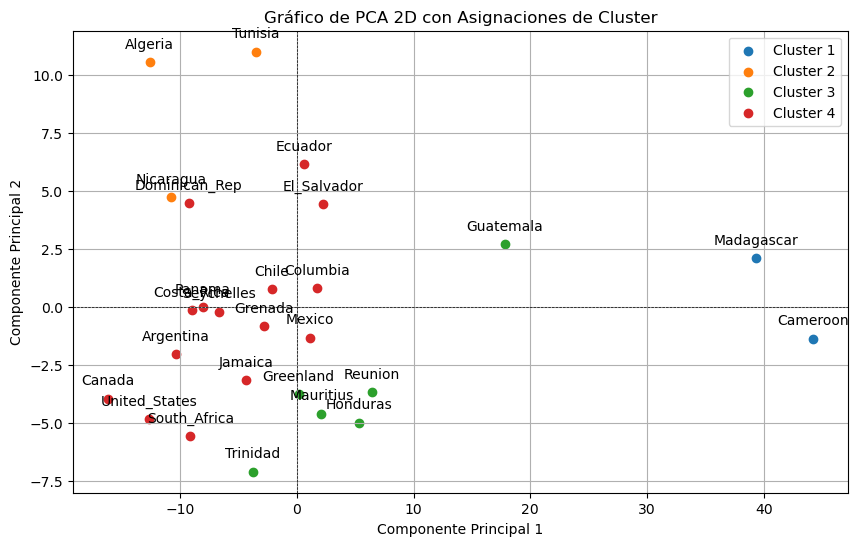

In [93]:

# Creamos un nuevo DataFrame para los componentes principales 2D
# Nos aseguramos de que df_pca tenga el mismo índice que df
df_pca = pd.DataFrame(data=principal_components, columns=['PC1', 'PC2'], index=df.index)


# Paso 2: Crear un gráfico de dispersión con colores para los clusters
plt.figure(figsize=(10, 6))  # Establecemos el tamaño del gráfico

# Recorremos las asignaciones únicas de clusters y trazamos puntos de datos con el mismo color
for cluster in np.unique(cluster_assignments):
    cluster_indices = df_pca.loc[cluster_assignments == cluster].index
    plt.scatter(df_pca.loc[cluster_indices, 'PC1'],
                df_pca.loc[cluster_indices, 'PC2'],
                label=f'Cluster {cluster}')  # Etiqueta para cada cluster
    # Anotamos cada punto con el nombre del país
    for i in cluster_indices:
        plt.annotate(i,
                     (df_pca.loc[i, 'PC1'], df_pca.loc[i, 'PC2']), fontsize=10,
                     textcoords="offset points",  # cómo posicionar el texto
                     xytext=(0,10),  # distancia del texto a los puntos (x,y)
                     ha='center')  # alineación horizontal puede ser izquierda, derecha o centro

# Líneas de referencia para los ejes x e y
plt.axhline(0, color='black', linestyle='--', linewidth=0.5)
plt.axvline(0, color='black', linestyle='--', linewidth=0.5)

plt.title("Gráfico de PCA 2D con Asignaciones de Cluster")
plt.xlabel("Componente Principal 1")
plt.ylabel("Componente Principal 2")
plt.legend()
plt.grid()
plt.show()




 6) Selección del número de clústers: Utilizar métodos como el del codo y la silueta para determinar el número óptimo de clústers.
 
 Una vez finalizado el análisis jerárquico, el siguiente paso es determinar el número más adecuado de clusters para nuestro conjunto de datos. Este número se contrastará con la propuesta obtenida del análisis jerárquico, que en nuestro caso sugiere 4 grupos o clusters.

Para este fin, aplicaremos diversos métodos, comenzando con el conocido método del codo:

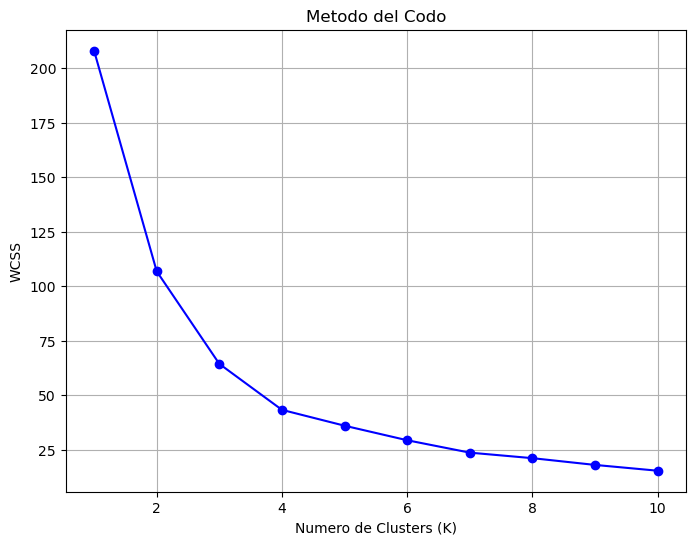

In [96]:
# Metodo del codo
# Creamos un array para almacenar los valores de WCSS para diferentes valores de K
wcss = []
    
for k in range(1, 11):  # Puedes elegir un rango diferente de valores de K
    kmeans = KMeans(n_clusters=k, random_state=0, n_init=10)
    kmeans.fit(df_std)
    wcss.append(kmeans.inertia_)  # Inserta es el valor de WCSS

# Graficamos los valores de WCSS frente al numero de grupos (K) y buscamos el punto "codo"
plt.figure(figsize=(8, 6))
plt.plot(range(1, 11), wcss, marker='o', linestyle='-', color='b')
plt.title('Metodo del Codo')
plt.xlabel('Numero de Clusters (K)')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

Observando el gráfico del método del codo, identificamos que el WCSS deja de reducirse significativamente a partir de 
$k=4$. Esta observación coincide con nuestro análisis previo de clustering jerárquico, reafirmando que un quinto cluster no aportaría una mejora sustancial.

Posteriormente, empleamos el método de la silueta para validar aún más nuestra elección del número óptimo de clusters. Este método evalúa la cohesión y separación de los clusters para diferentes valores de $K$ y el gráfico resultante nos proporcionará una visualización clara del puntaje de silueta promedio para cada valor de $K$, lo que nos ayudará a seleccionar el número de clusters que ofrece el mejor equilibrio.

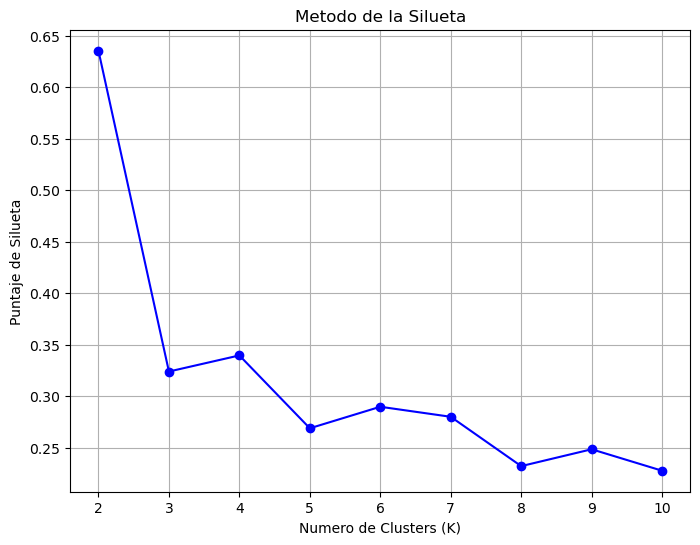

In [97]:

# Metodo de la silueta  
# Creamos un array para almacenar los puntajes de silueta para diferentes valores de K
silhouette_scores = []
    
# Ejecutamos el clustering K-means para un rango de valores de K y calculamos el puntaje de silueta para cada K
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=0)
    kmeans.fit(df_std)
    labels = kmeans.labels_
    silhouette_avg = silhouette_score(df_std, labels)
    silhouette_scores.append(silhouette_avg)
    
# Graficamos los puntajes de silueta frente al numero de clusters (K)
plt.figure(figsize=(8, 6))
plt.plot(range(2, 11), silhouette_scores, marker='o', linestyle='-', color='b')
plt.title('Metodo de la Silueta')
plt.xlabel('Numero de Clusters (K)')
plt.ylabel('Puntaje de Silueta')
plt.grid(True)
plt.show()


En nuestro caso, el método sugiere $k=2$ clusters como una solución óptima, pero considerando que esta elección podría ser demasiado simplista, el siguiente máximo local razonable es 4. Esto concuerda con el número de clusters que hemos estado considerando a lo largo de nuestro análisis.

7) Desarrollar un análisis no jerárquico mediante el algoritmo $k-means$.

Una vez que hemos determinado el número apropiado de clusters mediante análisis jerárquico y los diferentes métodos utilizados anteriormente, avanzamos hacia la construcción de nuestros grupos o clusters finales a través de un proceso no jerárquico. Este enfoque permite solidificar la estructura de clusters identificada en la etapa jerárquica, proporcionando una segmentación concreta y definida del conjunto de datos.

Utilizamos la función $KMeans()$  indicando que el número de cluster es 4. Observamos que, para fijar la generación de valores aleatorios idénticos en todos los ordenadores, necesitamos añadir la siguiente sentencia: 


In [98]:

# Analisis no jerarquico
# Configurar el número de clusters (k=4)
k = 4

# Inicializar el modelo KMeans
# 'n_clusters=k' indica el número de clusters a formar
# 'random_state=0' asegura la reproducibilidad de los resultados
# 'n_init=10' indica el número de veces que el algoritmo se ejecutará con diferentes centroides iniciales
kmeans = KMeans(n_clusters=k, random_state=0, n_init=10)


# Ajustar el modelo KMeans a los datos estandarizados
# 'df_std' es el DataFrame que contiene los datos previamente estandarizados
kmeans.fit(df_std)

# Obtener las etiquetas de los clusters para los datos
# 'kmeans.labels_' contiene la asignación de cada punto a un cluster
kmeans_cluster_labels = kmeans.labels_

# Creamos una nueva columna 'Cluster' y asignamos los valores de 'kmeans_cluster_labels' a ella
# 'Cluster4_v2' sera el nombre de la nueva columna en el DataFrame 'df'
df['Cluster4_v2'] = kmeans_cluster_labels

# Ahora 'df' contiene una nueva columna 'Cluster4_v2' con las asignaciones de cluster
# Imprimimos los valores de la columna 'Cluster4_v2' para verificar las asignaciones de cluster
print(df["Cluster4_v2"])

PAIS
Algeria          2
Cameroon         0
Madagascar       0
Mauritius        3
Reunion          3
Seychelles       1
South_Africa     1
Tunisia          2
Canada           1
Costa_Rica       1
Dominican_Rep    2
El_Salvador      1
Greenland        3
Grenada          1
Guatemala        3
Honduras         3
Jamaica          1
Mexico           3
Nicaragua        2
Panama           1
Trinidad         3
United_States    1
Argentina        1
Chile            1
Columbia         1
Ecuador          1
Name: Cluster4_v2, dtype: int32


8) Evalua la calidad de los grupos creados

El siguiente paso consiste en calcular y representar el coeficiente de silueta para cada observación dentro de los clusters determinados. El Gráfico de Silueta nos ayudará a evaluar la 'calidad' de cohesión y separación por observación en cada observación en los clusters.

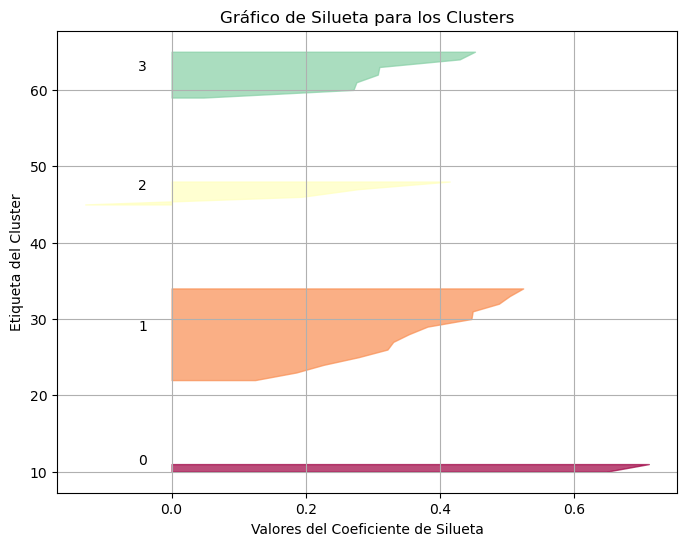

In [100]:
# Calculamos los valores de silueta para cada observación
silhouette_values = silhouette_samples(df_std, kmeans.labels_)
    
# Configuramos el tamaño de la figura para el gráfico
plt.figure(figsize=(8, 6))
y_lower = 10  # Inicio del margen inferior en el gráfico

# Iteramos sobre los 4 clusters para calcular los valores de silueta y dibujar el gráfico
for i in range(4):
    # Extraemos los valores de silueta para las observaciones en el cluster i
    ith_cluster_silhouette_values = silhouette_values[kmeans.labels_ == i]
    # Ordenamos los valores para que el gráfico sea más claro
    ith_cluster_silhouette_values.sort()
    
    # Calculamos donde terminarán las barras de silueta en el eje y
    size_cluster_i = ith_cluster_silhouette_values.shape[0]
    y_upper = y_lower + size_cluster_i
    
    # Elegimos un color para el cluster
    color = plt.cm.get_cmap("Spectral")(float(i) / 4)
    # Rellenamos el gráfico entre un rango en el eje y con los valores de silueta
    plt.fill_betweenx(np.arange(y_lower, y_upper),
                      0, ith_cluster_silhouette_values,
                      facecolor=color, edgecolor=color, alpha=0.7)
    # Etiquetamos las barras de silueta con el número de cluster en el eje y
    plt.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))
    # Actualizamos el margen inferior para el siguiente cluster
    y_lower = y_upper + 10  # 10 para el espacio entre clusters

# Títulos y etiquetas para el gráfico
plt.title("Gráfico de Silueta para los Clusters")
plt.xlabel("Valores del Coeficiente de Silueta")
plt.ylabel("Etiqueta del Cluster")
plt.grid(True)  # Añadimos una cuadrícula para mejor legibilidad
plt.show()  # Mostramos el gráfico resultante




El Gráfico de silueta resultante muestra la distribución de los coeficientes de silueta para cada clúster. Un coeficiente de silueta más alto sugiere que la observación está bien ajustada en su propio clúster y mal ajustada en clústers vecinos. Observando el gráfico el único cluster que tiene observaciones 'mal' clasificadas es el cluster 2.



 9) Caracterización de clústers: Describir las propiedades y características distintivas de cada clúster identificado.
 
 Con los clusters ya definidos, procedemos a visualizar su distribución espacial mediante un Análisis de Componentes Principales (ACP), lo que nos permite observar la agrupación de los datos en un espacio bidimensional.

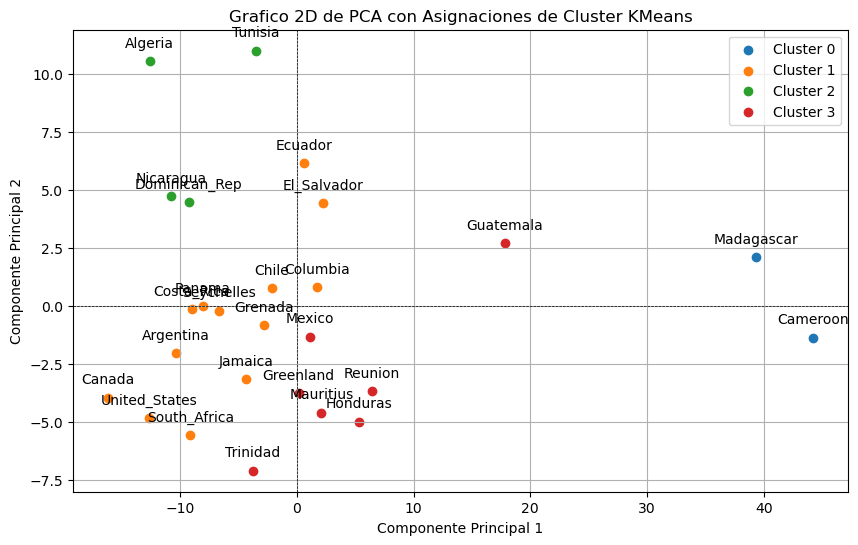

In [99]:
# Caracterizamos cada cluster
# Visualizacion de la distribucion espacial de los clusters

plt.figure(figsize=(10, 6))  # Definir el tamaño de la figura

# Iterar a traves de las etiquetas unicas de clusters y graficar puntos de datos con el mismo color
for cluster in np.unique(kmeans_cluster_labels):
    cluster_indices = df_pca.loc[kmeans_cluster_labels == cluster].index
    plt.scatter(df_pca.loc[cluster_indices, 'PC1'],
                df_pca.loc[cluster_indices, 'PC2'],
                label=f'Cluster {cluster}')  # Poner una etiqueta para cada cluster
    
    # Anotar cada punto con su respectivo indice
    for i in cluster_indices:
        plt.annotate(i,
                     (df_pca.loc[i, 'PC1'], df_pca.loc[i, 'PC2']),fontsize=10,
                     textcoords="offset points",  # Define como se posicionara el texto
                     xytext=(0,10),  # Define la distancia del texto a los puntos (x,y)
                     ha='center')  # Define la alineacion horizontal del texto

# Líneas de referencia para los ejes x e y
plt.axhline(0, color='black', linestyle='--', linewidth=0.5)
plt.axvline(0, color='black', linestyle='--', linewidth=0.5)

# Configurar el titulo y las etiquetas de los ejes del grafico
plt.title("Grafico 2D de PCA con Asignaciones de Cluster KMeans")
plt.xlabel("Componente Principal 1")
plt.ylabel("Componente Principal 2")
plt.legend()  # Mostrar la leyenda
plt.grid()  # Mostrar la cuadricula
plt.show()  # Mostrar el grafico

Para completar el proceso de caracterización, llevamos a cabo un análisis descriptivo de las variables originales dentro de cada cluster, lo que nos permite interpretar y entender las propiedades distintivas de cada grupo.

In [101]:
# Añadimos las etiquetas como una nueva columna al DataFrame original
df['Cluster'] = kmeans.labels_
# Ordenamos el DataFrame por la columna "Cluster"
df_sort = df.sort_values(by="Cluster")

# Agrupamos los datos por la columna 'Cluster' y calculamos la media de cada grupo
# Esto proporcionará las coordenadas de los centroides de los clusters en el espacio de los datos originales
cluster_centroids_orig = df_sort.groupby('Cluster').mean()
# Redondeamos los valores para facilitar la visualización
cluster_centroids_orig.round(2)
# 'cluster_centroids_orig' ahora contiene los centroides de cada cluster en el espacio de los datos originales


,m0,m25,m50,m75,w0,w25,w50,w75,Cluster4,Cluster4_v2
Cluster,,,,,,,,,,
0,36.00,29.50,15.00,6.00,38.00,33.00,18.50,6.50,1.00,0.0
1,62.46,45.23,24.15,8.54,67.46,49.54,27.23,10.54,4.00,1.0
2,62.00,48.75,27.50,12.25,66.00,52.50,31.25,14.50,2.50,2.0
3,58.00,41.86,21.29,6.86,62.00,44.86,24.14,8.29,3.14,3.0


Por ejemplo, los clusters 1 a 2 presentan una mayor esperanza de vida tanto para hombres como para mujeres en todas las etapas. Es notable que en la etapa inicial y media de la vida, son los clusters 1 y 2 los que exhiben una mayor esperanza, mientras que en la tercera edad, el cluster 2 destaca significativamente. 
El cluster 0 es el que muestra menor esperanza de vida en cualquier etapa. 

Este tipo de insights son fundamentales para la interpretación de los resultados y para comprender la naturaleza de los clusters identificados. 